# 08 — XGBoost et benchmarks supervisés étendus

Quatre régressions indépendantes, **16 entrées numériques + procédé / médiane**,
Charpy E(T) exploratoire avec température connue. Cohorte et plis des notebooks
02/05/06 inchangés : cinq externes, trois internes. XGBoost s'ajoute aux cinq
familles existantes ; sélection par MAE **interne** et nouvelle CV5 pour les
refits complets. Les résultats précédents sont relus et vérifiés, pas écrasés.
Le benchmark initial 13/itérative et les diagnostics factoriels restent historiques.
Ce notebook contient tout le code de cette expérience, sans package `src/`.

Grille fixée avant calcul : 12 configurations (profondeur 2/4/6, taux 0,03/0,1,
150/300 arbres), budget égal en nombre de configurations à RF/SVR. Objectif
quadratique, choix par MAE ; hist CPU, seed42, un thread par estimateur,
min_child_weight=5, subsample=colsample_bytree=0,8, reg_lambda=1, reg_alpha=0.
Aucun early stopping ni accès aux validations externes pour le réglage.
La médiane et l'encodage appris dans chaque train maintiennent une comparaison
à préparation identique ; la gestion native des NaN n'est pas étudiée ici.
Sources : [paramètres XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html),
[API](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor).


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import Memory, parallel_config
from threadpoolctl import threadpool_limits

SEED = 42
N_JOBS = 3  # recherches parallèles ; chaque forêt utilise un seul worker
PRIMARY_SET = 'A1b_16'
PRIMARY_IMPUTER = 'median'
TARGETS = ['yield_strength', 'uts', 'elongation', 'charpy_J']
CAT = 'weld_process'
PROCESS_COL = CAT
CORE13 = ['C', 'Si', 'Mn', 'S', 'P', 'current_A', 'voltage_V',
          'heat_input_kJmm', 'interpass_C', 'pwht_temp_C', 'pwht_time_h',
          'O_ppm', 'N_ppm']
CORE16 = CORE13 + ['Ni', 'Cr', 'Mo']
NONNEG = CORE16  # la température d'essai peut être négative
TARGET_UNITS = {'yield_strength': 'MPa', 'uts': 'MPa',
                'elongation': 'points de %', 'charpy_J': 'J'}
TARGET_NAMES = {'yield_strength': "Limite d'élasticité", 'uts': 'Résistance maximale',
                'elongation': 'Allongement', 'charpy_J': 'Énergie Charpy — exploratoire'}
MODEL_NAMES = {'median_y': 'Médiane de y', 'ridge': 'Ridge', 'svr_rbf': 'SVR RBF',
               'random_forest': 'Random Forest', 'knn': 'kNN'}
PARAM_GRIDS = {
    'median_y': {},
    'ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    'svr_rbf': {'model__regressor__C': [1, 10, 100],
                'model__regressor__gamma': ['scale', 0.05],
                'model__regressor__epsilon': [0.05, 0.2]},
    'random_forest': {'model__min_samples_leaf': [1, 2, 5],
                     'model__max_depth': [None, 10],
                     'model__max_features': [0.5, 1.0]},
    'knn': {'model__n_neighbors': [3, 5, 9, 15], 'model__p': [1, 2]},
}

def numeric_features(target):
    if target not in TARGETS:
        raise ValueError(f'Cible non prévue : {target}')
    return list(CORE16) + (['charpy_temp_C'] if target == 'charpy_J' else [])

def task_features(target):
    return numeric_features(target) + [CAT]

def eligible_rows(frame, target):
    # La température d'essai est une condition connue pour E(T), jamais imputée
    # pour fabriquer un couple Charpy dont la condition d'essai serait inconnue.
    mask = frame['in_strict13'] & frame[target].notna()
    if target == 'charpy_J':
        mask &= frame.charpy_temp_C.notna()
    return frame.loc[mask].copy()

def regression_metrics(y, prediction):
    y, prediction = np.asarray(y, float), np.asarray(prediction, float)
    if not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError('Labels/prédictions non finis.')
    return {'MAE': float(mean_absolute_error(y, prediction)),
            'RMSE': float(mean_squared_error(y, prediction) ** 0.5),
            'R2': float(r2_score(y, prediction)) if np.ptp(y)>0 else np.nan}

from sklearn.model_selection import KFold, GroupKFold
from scipy.stats import spearmanr
import cloudpickle
import copy
import subprocess
import sys
import os

def balanced_assignment(n, folds, seed):
    # Handles small/empty unlabeled pools; no label values are consulted.
    result=np.empty(n,dtype=int)
    order=np.random.default_rng(seed).permutation(n)
    result[order]=np.arange(n)%folds
    return result

def build_random_plan(frame,target,seed=SEED):
    candidate=frame.loc[frame.in_strict13 & ~frame.is_duplicate_excess].copy()
    if target=='charpy_J': candidate=candidate.loc[candidate.charpy_temp_C.notna()]
    candidate=candidate.sort_values('raw_row_id').reset_index(drop=True)
    plan=candidate[['raw_row_id','group']].copy()
    plan['target']=target
    plan['label_state']=np.where(candidate[target].notna(),'labeled','unlabeled')
    plan['outer_fold']=-1
    known=np.flatnonzero(candidate[target].notna())
    for fold,(_,va) in enumerate(KFold(5,shuffle=True,random_state=seed).split(known)):
        plan.loc[known[va],'outer_fold']=fold
    unknown=np.flatnonzero(candidate[target].isna())
    plan.loc[unknown,'outer_fold']=balanced_assignment(len(unknown),5,seed+100)
    for outer in range(5):
        col=f'inner_fold_when_outer{outer}'; plan[col]=-1
        labeled_train=np.flatnonzero((plan.outer_fold!=outer)&(plan.label_state=='labeled'))
        for fold,(_,va) in enumerate(KFold(3,shuffle=True,random_state=seed+outer+1).split(labeled_train)):
            plan.loc[labeled_train[va],col]=fold
        unlabeled_train=np.flatnonzero((plan.outer_fold!=outer)&(plan.label_state=='unlabeled'))
        plan.loc[unlabeled_train,col]=balanced_assignment(len(unlabeled_train),3,seed+1000+outer)
    assert not plan.duplicated('raw_row_id').any()
    return plan

def permitted_ids(plan,outer,inner=None):
    # Strict inductive access. Outer/inner validation inputs are not in the pool.
    train=plan.outer_fold!=outer
    if inner is not None:
        train &= plan[f'inner_fold_when_outer{outer}']!=inner
    labeled=plan.label_state=='labeled'
    valid=(plan.outer_fold==outer) if inner is None else (
        (plan.outer_fold!=outer)&(plan[f'inner_fold_when_outer{outer}']==inner))
    return {'labeled_train':plan.loc[train&labeled,'raw_row_id'].to_numpy(),
            'unlabeled_train':plan.loc[train&~labeled,'raw_row_id'].to_numpy(),
            'labeled_valid':plan.loc[valid&labeled,'raw_row_id'].to_numpy()}

def random_partitions(frame,plan,outer):
    access=permitted_ids(plan,outer)
    train=frame.loc[frame.raw_row_id.isin(access['labeled_train'])].sort_values('raw_row_id').reset_index(drop=True)
    valid=frame.loc[frame.raw_row_id.isin(access['labeled_valid'])].sort_values('raw_row_id').reset_index(drop=True)
    assert set(train.raw_row_id).isdisjoint(valid.raw_row_id)
    assert train[plan.target.iloc[0]].notna().all() and valid[plan.target.iloc[0]].notna().all()
    return train,valid

def random_inner_splits(train,plan,outer):
    folds=plan.set_index('raw_row_id').loc[train.raw_row_id,f'inner_fold_when_outer{outer}'].to_numpy()
    assert set(folds)=={0,1,2}
    return [(np.flatnonzero(folds!=k),np.flatnonzero(folds==k)) for k in range(3)]

def condition_signature(frame,columns):
    # Exact available values, including an explicit unknown marker; never impute.
    # Equality of partial signatures is a proxy, not proof of the same specimen.
    def token(v):
        if pd.isna(v): return None
        return v.item() if isinstance(v,np.generic) else v
    return frame[columns].apply(lambda row:json.dumps([token(v) for v in row],
                               ensure_ascii=False,separators=(',',':')),axis=1)

def train_seen_signatures(train,valid,columns):
    return condition_signature(valid,columns).isin(set(condition_signature(train,columns)))

def detached_pipeline(fitted):
    model=copy.deepcopy(fitted)
    model.memory=None
    return model

def dump_pipeline(fitted,path,metadata,probe):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    exported=detached_pipeline(fitted)
    with path.open('wb') as stream: cloudpickle.dump(exported,stream,protocol=5)
    with path.open('rb') as stream: loaded=cloudpickle.load(stream)
    np.testing.assert_allclose(loaded.predict(probe),fitted.predict(probe),rtol=1e-10,atol=1e-8)
    metadata=dict(metadata,artifact_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                  serialization='cloudpickle_protocol5',versions=VERSIONS)
    path.with_suffix('.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False)+'\n')
    return metadata

import xgboost
from xgboost import XGBRegressor

PROTOCOLS = ['random', 'grouped']
PROTOCOL_VERSION = 'salh-xgboost-v1'
MODEL_NAMES['xgboost'] = 'XGBoost'
PARAM_GRIDS['xgboost'] = {
    'model__max_depth': [2, 4, 6],
    'model__learning_rate': [0.03, 0.1],
    'model__n_estimators': [150, 300],
}
FAMILY_ORDER = list(PARAM_GRIDS)  # égalités : ordre historique, XGBoost dernier

def outer_partitions(frame, target, outer_fold):
    eligible = eligible_rows(frame, target)
    train = eligible.loc[eligible.outer_fold != outer_fold].reset_index(drop=True)
    valid = eligible.loc[eligible.outer_fold == outer_fold].reset_index(drop=True)
    if train.empty or valid.empty:
        raise ValueError(f'Partition vide : {target}, pli {outer_fold}')
    if not set(train.group).isdisjoint(valid.group):
        raise AssertionError('Un groupe externe est partagé entre train et validation.')
    return train, valid

def inner_splits(train, outer_fold):
    col = f'inner_fold_when_outer{outer_fold}'
    if not set(train[col].unique()).issubset({0, 1, 2}):
        raise AssertionError('Les lignes externes ne doivent pas entrer dans les plis internes.')
    splits = []
    for inner_fold in range(3):
        tr = np.flatnonzero(train[col].to_numpy() != inner_fold)
        va = np.flatnonzero(train[col].to_numpy() == inner_fold)
        if len(tr) < 15 or len(va) < 2:
            raise ValueError('Effectif interne insuffisant pour les grilles prévues.')
        if not set(train.iloc[tr].group).isdisjoint(train.iloc[va].group):
            raise AssertionError('Un groupe interne est partagé.')
        splits.append((tr, va))
    return splits


def grouped_full_splits(train):
    partitions=list(GroupKFold(5).split(train,groups=train.group))
    for tr,va in partitions:
        assert set(train.iloc[tr].group).isdisjoint(train.iloc[va].group)
    return partitions


In [2]:
class FoldPreprocessor(BaseEstimator, TransformerMixin):
    """À ajuster sur les lignes d'entraînement d'un pli uniquement.

    1. standardisation des entrées numériques (moyenne/écart-type du train, NaN ignorés) ;
    2. one-hot du procédé (catégories du train ; inconnue -> vecteur nul) ;
    3. imputation : 'iterative' (IterativeImputer/BayesianRidge, init médiane, ordre ascendant,
       max_iter=100, tol=1e-3, random_state=42, bornes physiques >= 0) ou 'median' ;
    4. PWHT : un couple (température, durée) imputé est projeté sur le couple réel du train
       le plus proche (distance en écarts-types du train), en respectant une valeur observée.
    Une colonne entièrement absente du train est refusée plutôt que fabriquée.
    Sortie : entrées standardisées + indicatrices du procédé. Les cibles n'entrent jamais ici.
    """

    def __init__(self, num_cols, cat_col=PROCESS_COL, method='median', max_iter=100,
                 tol=1e-3, random_state=SEED):
        self.num_cols, self.cat_col, self.method = num_cols, cat_col, method
        self.max_iter, self.tol, self.random_state = max_iter, tol, random_state

    def _encode(self, X):
        if 'charpy_temp_C' in self.num_cols and X['charpy_temp_C'].isna().any():
            raise ValueError("Température Charpy requise ; aucune condition d'essai ne peut être imputée.")
        Z = (X[self.num_cols].to_numpy(float) - self.mu_) / self.sd_
        C = np.stack([(X[self.cat_col] == c).to_numpy(float) for c in self.cats_], axis=1) \
            if self.cat_col else np.empty((len(X), 0))
        return np.hstack([Z, C])

    def fit(self, X, y=None):
        Xn = X[self.num_cols].astype(float)
        empty = Xn.columns[Xn.notna().sum() == 0].tolist()
        if empty:
            raise ValueError(f'Colonnes entièrement absentes du train : {empty}')
        self.mu_ = Xn.mean().to_numpy()
        self.sd_ = Xn.std(ddof=0).replace(0, 1).to_numpy()
        self.cats_ = sorted(X[self.cat_col].dropna().unique()) if self.cat_col else []
        Z = self._encode(X)
        lo = np.full(Z.shape[1], -np.inf)
        for i, c in enumerate(self.num_cols):
            if c in NONNEG:
                lo[i] = (0 - self.mu_[i]) / self.sd_[i]
        if self.method == 'iterative':
            self.imp_ = IterativeImputer(estimator=BayesianRidge(), initial_strategy='median',
                                         imputation_order='ascending', max_iter=self.max_iter,
                                         tol=self.tol, random_state=self.random_state,
                                         skip_complete=False, min_value=lo, keep_empty_features=True)
        elif self.method == 'median':
            self.imp_ = SimpleImputer(strategy='median', keep_empty_features=True)
        else:
            raise ValueError(self.method)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            self.imp_.fit(Z)
        self.converged_ = (self.method != 'iterative') or (self.imp_.n_iter_ < self.max_iter)
        self.n_iter_ = getattr(self.imp_, 'n_iter_', 0)
        if not self.converged_:
            raise RuntimeError('Imputation itérative non convergée : réviser le schéma dans le train.')
        # couples PWHT réels du train
        self.pw_idx_ = [self.num_cols.index(c) for c in ('pwht_temp_C', 'pwht_time_h')
                        if c in self.num_cols]
        if len(self.pw_idx_) == 2:
            P = Z[:, self.pw_idx_]
            self.pw_pairs_ = np.unique(P[~np.isnan(P).any(axis=1)], axis=0)
            if len(self.pw_pairs_) == 0:
                raise ValueError('Aucun couple PWHT complet dans le train.')
        return self

    def transform(self, X):
        Z = self._encode(X)
        miss = np.isnan(Z)
        out = self.imp_.transform(Z)
        if len(self.pw_idx_) == 2 and len(self.pw_pairs_):
            i, j = self.pw_idx_
            for r in np.where(miss[:, i] | miss[:, j])[0]:
                cand = self.pw_pairs_
                if not miss[r, i]:   # température observée : couples compatibles seulement
                    cand = cand[np.isclose(cand[:, 0], Z[r, i])]
                if not miss[r, j]:
                    cand = cand[np.isclose(cand[:, 1], Z[r, j])]
                if len(cand) == 0:
                    raise ValueError(f'Aucun couple PWHT compatible pour la ligne {X.index[r]}.')
                best = cand[np.argmin(((cand - out[r, [i, j]]) ** 2).sum(axis=1))]
                out[r, i] = Z[r, i] if not miss[r, i] else best[0]
                out[r, j] = Z[r, j] if not miss[r, j] else best[1]
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array([str(c) for c in self.num_cols] + [f'{self.cat_col}={c}' for c in self.cats_], dtype=object)


In [3]:
def make_pipeline(model_name, target, memory=None):
    if model_name == 'median_y':
        # DummyRegressor ignore les valeurs de X ; seule la médiane de y est apprise.
        return Pipeline([('model', DummyRegressor(strategy='median'))])
    estimators = {
        'xgboost': XGBRegressor(objective='reg:squarederror', booster='gbtree',
            tree_method='hist', device='cpu', random_state=SEED, n_jobs=1,
            min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0, reg_alpha=0.0, gamma=0.0, max_bin=256,
            eval_metric='mae', verbosity=0),
        'ridge': Ridge(),
        'svr_rbf': TransformedTargetRegressor(
            regressor=SVR(kernel='rbf'), transformer=StandardScaler()),
        'random_forest': RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
        'knn': KNeighborsRegressor(weights='uniform'),
    }
    if model_name not in estimators:
        raise ValueError(model_name)
    return Pipeline([
        ('preprocess', FoldPreprocessor(numeric_features(target), cat_col=CAT,
                                       method=PRIMARY_IMPUTER, random_state=SEED)),
        ('model', estimators[model_name]),
    ], memory=memory)


def search_pipeline(train,target,model,cv,memory=None):
    search=GridSearchCV(make_pipeline(model,target,memory),PARAM_GRIDS[model],
        scoring='neg_mean_absolute_error',cv=cv,refit=True,n_jobs=N_JOBS,
        error_score='raise',return_train_score=False)
    with parallel_config(backend='threading'),threadpool_limits(limits=1):
        search.fit(train[task_features(target)],train[target])
    return search

def choose_inner_family(rows):
    """Never use outer MAE/R2 to select the family; deterministic tie rule."""
    if rows.model.duplicated().any() or not np.isfinite(rows.inner_MAE).all():
        raise ValueError('Familles dupliquées ou scores internes invalides.')
    return min(rows.to_dict('records'),
               key=lambda r: (r['inner_MAE'], FAMILY_ORDER.index(r['model'])))


def benchmark_summary(scores, predictions):
    keys = ['protocol', 'target', 'model']
    summary = scores.groupby(keys).agg(MAE_mean=('MAE','mean'), MAE_sd=('MAE','std'),
        RMSE_mean=('RMSE','mean'), R2_mean=('R2','mean'), R2_sd=('R2','std'),
        folds=('outer_fold','nunique')).reset_index()
    pooled = pd.DataFrame([dict(zip(keys,key), **{'OOF_'+k:v for k,v in
        regression_metrics(g.y_true,g.y_pred).items()}) for key,g in predictions.groupby(keys)])
    return summary.merge(pooled,on=keys,validate='one_to_one')


## Données, unités et identité des comparaisons

Le master non imputé conserve les NaN (`N` signifie non rapporté, jamais zéro),
les quarantaines et les nettoyages déterministes. C/Si/Mn/S/P/Ni/Cr/Mo en %
massique ; O/N en ppm ; courant A, tension V, apport kJ/mm ; températures °C,
durée PWHT h. YS/UTS en MPa, allongement en points de %, Charpy en J.
Ni les autres cibles, ni les identifiants/groupes ne sont des prédicteurs.
Les hashes des sources et la reproduction du plan aléatoire sont contrôlés.


In [4]:
PROJECT_ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'sujet.md').is_file())
DATA=PROJECT_ROOT/'data/processed/modeling'
EXP=PROJECT_ROOT/'data/processed/experiments'
OUT=EXP/PROTOCOL_VERSION.replace('-','_')
MODELS=PROJECT_ROOT/'models'/PROTOCOL_VERSION.replace('-','_')
OUT.mkdir(parents=True,exist_ok=True); MODELS.mkdir(parents=True,exist_ok=True)
STARTED=time.perf_counter()
VERSIONS={'python':platform.python_version(),'sklearn':sklearn.__version__,
    'xgboost':xgboost.__version__,'numpy':np.__version__,'pandas':pd.__version__,
    'joblib':joblib.__version__,'cloudpickle':cloudpickle.__version__}
SOURCE_DIRS={'random':EXP/'salh_random_kfold_v1','grouped':EXP/'salh_group_kfold_v1',
             'coreg':EXP/'salh_coreg_v1'}
source_hashes={}
for folder in [DATA, EXP/'salh_diagnostics_v1', *SOURCE_DIRS.values()]:
    manifest=json.loads((folder/'manifest.json').read_text())
    source_hashes[str(folder.relative_to(PROJECT_ROOT))+'/manifest.json']=hashlib.sha256((folder/'manifest.json').read_bytes()).hexdigest()
    for filename,digest in manifest['files'].items():
        assert hashlib.sha256((folder/filename).read_bytes()).hexdigest()==digest,(folder,filename)
preparation_manifest=json.loads((DATA/'manifest.json').read_text())
assert hashlib.sha256((PROJECT_ROOT/'data/raw/welddb.data').read_bytes()).hexdigest()==preparation_manifest['raw_sha256']
master=pd.read_csv(DATA/'master.csv')
folds=pd.read_csv(DATA/'folds.csv')
data=master.loc[master.in_strict13 & ~master.is_duplicate_excess].merge(folds,on=['raw_row_id','group'],validate='one_to_one')
assert len(data)==1555 and data.group.nunique()==44
plans={t:build_random_plan(data,t) for t in TARGETS}
saved_plan=pd.read_csv(SOURCE_DIRS['random']/'random_fold_assignments.csv')
for t in TARGETS:
    pd.testing.assert_frame_equal(plans[t],saved_plan.loc[saved_plan.target==t].reset_index(drop=True),check_dtype=False)
def save_csv(frame,name):
    frame.to_csv(OUT/name,index=False); return frame
save_csv(saved_plan,'random_fold_assignments.csv')
save_csv(folds,'grouped_fold_assignments.csv')
old_scores={p:pd.read_csv(SOURCE_DIRS[p]/'outer_metrics.csv').assign(protocol=p) for p in PROTOCOLS}
old_preds={p:pd.read_csv(SOURCE_DIRS[p]/'outer_predictions.csv').assign(protocol=p) for p in PROTOCOLS}

def partitions(protocol,target,outer):
    if protocol=='random':
        train,valid=random_partitions(data,plans[target],outer)
        cv=random_inner_splits(train,plans[target],outer)
    else:
        train,valid=outer_partitions(data,target,outer)
        cv=inner_splits(train,outer)
    assert set(train.raw_row_id).isdisjoint(valid.raw_row_id)
    assert len(cv)==3
    for tr,va in cv:
        assert set(tr).isdisjoint(va) and len(tr)+len(va)==len(train)
    return train,valid,cv

def export_model(fitted,protocol,target,role,train,valid=None,outer=-1,**extra):
    path=MODELS/protocol/role/f'{target}_fold{outer}.pkl'
    meta={'role':role,'protocol':protocol,'protocol_version':PROTOCOL_VERSION,
        'target':target,'outer_fold':outer,'features':task_features(target),
        'unit':TARGET_UNITS[target],'feature_set':PRIMARY_SET,'imputer':PRIMARY_IMPUTER,
        'train_raw_row_ids':train.raw_row_id.tolist(),'train_groups':sorted(train.group.unique()),
        'valid_raw_row_ids':[] if valid is None else valid.raw_row_id.tolist(),
        'valid_groups':[] if valid is None else sorted(valid.group.unique()),
        'raw_sha256':preparation_manifest['raw_sha256'],**extra}
    probe=(train if valid is None else valid)[task_features(target)].head(10)
    saved=dump_pipeline(fitted,path,meta,probe)
    return dict(meta,path=str(path.relative_to(PROJECT_ROOT)),sha256=saved['artifact_sha256'])

display(pd.DataFrame([{'target':t,'unit':TARGET_UNITS[t],'labels':len(eligible_rows(data,t))} for t in TARGETS]))
print('Versions :',VERSIONS)


,target,unit,labels
0,yield_strength,MPa,706
1,uts,MPa,677
2,elongation,points de %,631
3,charpy_J,J,861


Versions : {'python': '3.14.8', 'sklearn': '1.9.1', 'xgboost': '3.4.1', 'numpy': '2.5.3', 'pandas': '3.0.6', 'joblib': '1.6.0', 'cloudpickle': '3.1.2'}


## Entraînement imbriqué et sélection à six familles

12 configurations × 3 validations internes + refit externe par cible/pli.
Les cinq anciennes familles conservent leurs résultats. Leurs paramètres
optimaux sont vérifiés contre leurs recherches internes. La sélection à six
familles compare seulement leurs MAE internes. Si une famille historique est
retenue, son pipeline est réentraîné sur le train externe et doit reproduire
ses anciennes prédictions. Aucun refit complet n'entre dans une évaluation.


In [5]:
xgb_scores=[]; xgb_preds=[]; inner_rows=[]; selected_rows=[]; selected_preds=[]; artifacts=[]
for protocol in PROTOCOLS:
    if protocol=='random':
        previous_inner=pd.read_csv(SOURCE_DIRS[protocol]/'inner_search.csv')
    else:
        previous_inner=pd.read_csv(EXP/'salh_diagnostics_v1/sensitivity_inner_search.csv')
        previous_inner=previous_inner.loc[(previous_inner.feature_set==PRIMARY_SET)&(previous_inner.imputer==PRIMARY_IMPUTER)]
    for target in TARGETS:
        for outer in range(5):
            train,valid,cv=partitions(protocol,target,outer); features=task_features(target)
            previous=old_scores[protocol].loc[(old_scores[protocol].target==target)&(old_scores[protocol].outer_fold==outer)]
            assert set(previous.model)==set(FAMILY_ORDER[:-1])
            for row in previous.itertuples():
                if row.model=='median_y' and protocol=='grouped': continue
                inner=previous_inner.loc[(previous_inner.target==target)&(previous_inner.outer_fold==outer)&(previous_inner.model==row.model)].sort_values('candidate')
                winner=inner.loc[inner.inner_MAE.idxmin()]
                assert json.loads(row.best_params)==json.loads(winner.params)
                np.testing.assert_allclose(row.inner_MAE,winner.inner_MAE)
            started=time.perf_counter()
            search=search_pipeline(train,target,'xgboost',cv)
            pred=search.predict(valid[features]); pp=valid[['raw_row_id','group']].assign(
                protocol=protocol,target=target,model='xgboost',outer_fold=outer,
                y_true=valid[target].to_numpy(),y_pred=pred)
            row={'protocol':protocol,'target':target,'model':'xgboost','outer_fold':outer,
                'n_train':len(train),'n_valid':len(valid),'inner_MAE':-search.best_score_,
                'best_params':json.dumps(search.best_params_,sort_keys=True),
                'elapsed_seconds':time.perf_counter()-started,**regression_metrics(valid[target],pred)}
            xgb_scores.append(row); xgb_preds.append(pp)
            for i,params in enumerate(search.cv_results_['params']):
                inner_rows.append({'protocol':protocol,'target':target,'model':'xgboost','outer_fold':outer,
                    'candidate':i,'params':json.dumps(params,sort_keys=True),
                    'inner_MAE':-search.cv_results_['mean_test_score'][i],
                    **{f'inner{k}_MAE':-search.cv_results_[f'split{k}_test_score'][i] for k in range(3)}})
            artifacts.append(export_model(search.best_estimator_,protocol,target,'outer_xgboost',train,valid,outer,
                family='xgboost',best_params=search.best_params_,inner_MAE=-search.best_score_,
                evaluation=regression_metrics(valid[target],pred)))
            chosen=choose_inner_family(pd.concat([previous,pd.DataFrame([row])],ignore_index=True))
            family=chosen['model']
            if family=='xgboost': fitted=search.best_estimator_; chosen_pp=pp
            else:
                fitted=make_pipeline(family,target).set_params(**json.loads(chosen['best_params']))
                with threadpool_limits(limits=1): fitted.fit(train[features],train[target])
                chosen_pp=old_preds[protocol].loc[(old_preds[protocol].target==target)&
                    (old_preds[protocol].outer_fold==outer)&(old_preds[protocol].model==family)].copy()
                aligned=chosen_pp.set_index('raw_row_id').loc[valid.raw_row_id]
                np.testing.assert_allclose(aligned.y_true,valid[target],rtol=1e-10,atol=1e-8)
                np.testing.assert_allclose(aligned.y_pred,fitted.predict(valid[features]),rtol=1e-10,atol=1e-8)
            selected_rows.append(dict(chosen,model='inner_selected',selected_family=family))
            selected_preds.append(chosen_pp.assign(model='inner_selected'))
            artifacts.append(export_model(fitted,protocol,target,'outer_selected',train,valid,outer,
                family=family,best_params=json.loads(chosen['best_params']),inner_MAE=chosen['inner_MAE'],
                evaluation=regression_metrics(chosen_pp.y_true,chosen_pp.y_pred)))
            for records,name in [(xgb_scores,'xgboost_outer_metrics.csv'),(inner_rows,'xgboost_inner_search.csv'),
                                 (selected_rows,'inner_selected_metrics.csv')]: save_csv(pd.DataFrame(records),name)
            save_csv(pd.concat(xgb_preds,ignore_index=True),'xgboost_outer_predictions.csv')
            save_csv(pd.concat(selected_preds,ignore_index=True),'inner_selected_predictions.csv')
            print(f'{protocol} {target} pli {outer}: XGBoost MAE={row["MAE"]:.3f}, R²={row["R2"]:.3f}; choix interne={family}',flush=True)


random yield_strength pli 0: XGBoost MAE=22.009, R²=0.865; choix interne=xgboost


random yield_strength pli 1: XGBoost MAE=26.823, R²=0.843; choix interne=xgboost


random yield_strength pli 2: XGBoost MAE=28.218, R²=0.750; choix interne=xgboost


random yield_strength pli 3: XGBoost MAE=25.648, R²=0.818; choix interne=xgboost


random yield_strength pli 4: XGBoost MAE=28.970, R²=0.804; choix interne=xgboost


...

grouped charpy_J pli 0: XGBoost MAE=27.991, R²=0.007; choix interne=svr_rbf


grouped charpy_J pli 1: XGBoost MAE=32.701, R²=-0.309; choix interne=svr_rbf


grouped charpy_J pli 2: XGBoost MAE=27.600, R²=0.133; choix interne=median_y


grouped charpy_J pli 3: XGBoost MAE=54.660, R²=0.148; choix interne=xgboost


grouped charpy_J pli 4: XGBoost MAE=34.299, R²=0.365; choix interne=median_y


## Benchmarks communs : supervisés et COREG

Les moyennes/SD des cinq plis sont séparées des scores OOF. Vérification des
IDs, labels, groupes et plis pour toutes les prédictions, y compris COREG.
Les anciennes sélections COREG `supervised_inner_selected` désignent cinq
familles ; elles sont retirées du tableau courant au profit de la sélection
à six familles. Les entraînements COREG et ses contrôles restent identiques.


In [6]:
scores=pd.concat([*old_scores.values(),pd.DataFrame(xgb_scores),pd.DataFrame(selected_rows)],ignore_index=True)
predictions=pd.concat([*old_preds.values(),*xgb_preds,*selected_preds],ignore_index=True)
assert len(scores)==280 and len(inner_rows)==480
assert not scores.duplicated(['protocol','target','model','outer_fold']).any()
for (protocol,target,model),g in predictions.groupby(['protocol','target','model']):
    assert g.raw_row_id.is_unique and set(g.raw_row_id)==set(eligible_rows(data,target).raw_row_id)
    for outer,pp in g.groupby('outer_fold'):
        _,valid,_=partitions(protocol,target,outer)
        aligned=pp.set_index('raw_row_id').loc[valid.raw_row_id]
        np.testing.assert_array_equal(aligned.group,valid.group)
        np.testing.assert_allclose(aligned.y_true,valid[target])
        row=scores.loc[(scores.protocol==protocol)&(scores.target==target)&(scores.model==model)&(scores.outer_fold==outer)].iloc[0]
        for key,value in regression_metrics(pp.y_true,pp.y_pred).items(): np.testing.assert_allclose(row[key],value)
summary=benchmark_summary(scores,predictions)
save_csv(scores,'benchmark_outer_metrics.csv'); save_csv(predictions,'benchmark_outer_predictions.csv')
save_csv(summary,'metrics_summary.csv')
coreg_scores=pd.read_csv(SOURCE_DIRS['coreg']/'outer_metrics.csv').rename(columns={'method':'model'})
coreg_preds=pd.read_csv(SOURCE_DIRS['coreg']/'outer_predictions.csv').rename(columns={'method':'model'})
coreg_scores=coreg_scores.loc[coreg_scores.model!='supervised_inner_selected']
coreg_preds=coreg_preds.loc[coreg_preds.model!='supervised_inner_selected']
for (protocol,target,outer),g in coreg_preds.groupby(['protocol','target','outer_fold']):
    _,valid,_=partitions(protocol,target,outer)
    for _,pp in g.groupby('model'):
        assert pp.raw_row_id.is_unique and set(pp.raw_row_id)==set(valid.raw_row_id)
        np.testing.assert_allclose(pp.set_index('raw_row_id').loc[valid.raw_row_id,'y_true'],valid[target])
combined=benchmark_summary(pd.concat([scores,coreg_scores],ignore_index=True),pd.concat([predictions,coreg_preds],ignore_index=True))
save_csv(combined,'supervised_coreg_summary.csv')
display(summary.loc[summary.model.isin(['xgboost','inner_selected'])])


,protocol,target,model,MAE_mean,MAE_sd,RMSE_mean,R2_mean,R2_sd,folds,OOF_MAE,OOF_RMSE,OOF_R2
0,grouped,charpy_J,inner_selected,36.266800,12.770580,46.358322,0.058437,0.118884,5,36.835656,47.982284,0.097244
6,grouped,charpy_J,xgboost,35.450092,11.126181,45.293400,0.068690,0.247369,5,35.570978,46.260979,0.160852
7,grouped,elongation,inner_selected,3.278409,0.374284,4.140602,0.259525,0.137827,5,3.261115,4.145720,0.278332
13,grouped,elongation,xgboost,3.322207,0.381227,4.196361,0.237605,0.147883,5,3.296861,4.190321,0.262721
14,grouped,uts,inner_selected,55.691064,12.936448,70.250047,0.306544,0.215245,5,55.042295,70.724631,0.375123
20,grouped,uts,xgboost,50.215342,6.720214,65.164708,0.392200,0.178275,5,49.581066,64.690964,0.477194
21,grouped,yield_strength,inner_selected,54.363213,9.819509,70.263494,0.366818,0.167087,5,55.146555,72.248183,0.383085
27,grouped,yield_strength,xgboost,54.363213,9.819509,70.263494,0.366818,0.167087,5,55.146555,72.248183,0.383085
28,random,charpy_J,inner_selected,14.150793,0.724118,19.707272,0.844820,0.026473,5,14.150308,19.744350,0.847140
34,random,charpy_J,xgboost,14.150793,0.724118,19.707272,0.844820,0.026473,5,14.150308,19.744350,0.847140


## CV5 complète et index de sélection actualisé

CV5 aléatoire seed1042 sur les lignes triées, ou GroupKFold5 sans shuffle.
Scores de choix et refits pour l'inférence : aucun test indépendant.
Les cinq familles historiques gardent leurs recherches complètes vérifiées.
XGBoost est réglé séparément sur exactement les mêmes plis ; un nouvel index
choisit la famille parmi les six, sans consulter les métriques externes.


In [7]:
full_rows=[]; full_summary=[]; final_choices=[]
for protocol in PROTOCOLS:
    previous=pd.read_csv(SOURCE_DIRS[protocol]/'full_refit_summary.csv').assign(protocol=protocol)
    old_inner=pd.read_csv(SOURCE_DIRS[protocol]/'full_refit_inner_search.csv')
    for target in TARGETS:
        train=eligible_rows(data,target).sort_values('raw_row_id').reset_index(drop=True)
        cv=list(KFold(5,shuffle=True,random_state=SEED+1000).split(train)) if protocol=='random' else grouped_full_splits(train)
        for old in previous.loc[previous.target==target].itertuples():
            candidates=old_inner.loc[(old_inner.target==target)&(old_inner.family==old.family)].sort_values('candidate')
            best=candidates.loc[candidates.CV_MAE.idxmin()]
            np.testing.assert_allclose(old.selection_CV_MAE,best.CV_MAE)
            assert json.loads(old.best_params)==json.loads(best.params)
            path=PROJECT_ROOT/old.path
            assert hashlib.sha256(path.read_bytes()).hexdigest()==old.sha256
            meta=json.loads(path.with_suffix('.json').read_text())
            assert meta['train_raw_row_ids']==train.raw_row_id.tolist()
        search=search_pipeline(train,target,'xgboost',cv)
        for i,params in enumerate(search.cv_results_['params']):
            full_rows.append({'protocol':protocol,'target':target,'family':'xgboost','candidate':i,
                'params':json.dumps(params,sort_keys=True),'CV_MAE':-search.cv_results_['mean_test_score'][i],
                **{f'fold{k}_MAE':-search.cv_results_[f'split{k}_test_score'][i] for k in range(5)}})
        entry=export_model(search.best_estimator_,protocol,target,'full_xgboost',train,
            family='xgboost',best_params=search.best_params_,selection_CV_MAE=-search.best_score_,
            selection_cv='KFold5 shuffled seed1042' if protocol=='random' else 'GroupKFold5 shuffle=False',
            independent_test_evaluated=False,do_not_use_for_fold_evaluation=True)
        artifacts.append(entry)
        options=previous.loc[previous.target==target].to_dict('records')+[dict(entry,best_params=json.dumps(search.best_params_,sort_keys=True))]
        full_summary.extend(options)
        final_choices.append(min(options,key=lambda r:(r['selection_CV_MAE'],FAMILY_ORDER.index(r['family']))))
        print('Refit',protocol,target,'XGBoost CV MAE=',round(-search.best_score_,3),flush=True)
save_csv(pd.DataFrame(full_rows),'xgboost_full_refit_inner_search.csv')
save_csv(pd.DataFrame(full_summary),'full_refit_summary.csv')
save_csv(pd.DataFrame(final_choices),'selected_final_models.csv')
save_csv(pd.DataFrame(artifacts),'model_artifacts.csv')
(MODELS/'selected_models.json').write_text(json.dumps(final_choices,indent=2,ensure_ascii=False)+'\n')
display(pd.DataFrame(final_choices)[['protocol','target','family','selection_CV_MAE','best_params']])


Refit random yield_strength XGBoost CV MAE= 26.698


Refit random uts XGBoost CV MAE= 21.609


Refit random elongation XGBoost CV MAE= 1.919


Refit random charpy_J XGBoost CV MAE= 13.437


Refit grouped yield_strength XGBoost CV MAE= 57.742


Refit grouped uts XGBoost CV MAE= 49.094


Refit grouped elongation XGBoost CV MAE= 3.252


Refit grouped charpy_J XGBoost CV MAE= 32.822


,protocol,target,family,selection_CV_MAE,best_params
0,random,yield_strength,xgboost,26.697646,"{""model__learning_rate"": 0.1, ""model__max_dept..."
1,random,uts,xgboost,21.608512,"{""model__learning_rate"": 0.1, ""model__max_dept..."
2,random,elongation,xgboost,1.918983,"{""model__learning_rate"": 0.1, ""model__max_dept..."
3,random,charpy_J,xgboost,13.437173,"{""model__learning_rate"": 0.1, ""model__max_dept..."
4,grouped,yield_strength,xgboost,57.742301,"{""model__learning_rate"": 0.1, ""model__max_dept..."
5,grouped,uts,svr_rbf,46.555155,"{""model__regressor__C"": 10, ""model__regressor_..."
6,grouped,elongation,xgboost,3.251647,"{""model__learning_rate"": 0.1, ""model__max_dept..."
7,grouped,charpy_J,random_forest,32.374768,"{""model__max_depth"": 10, ""model__max_features""..."


## Rechargement indépendant, figures et manifeste

Les 88 exports sont rechargés dans un Python neuf sans exécuter les cellules
notebook : 40 XGBoost externes, 40 nouvelles sélections externes, huit refits.
Les 80 modèles externes reproduisent toutes leurs prédictions OOF ; les huit
refits reproduisent une sonde, sans mesure de généralisation. Les nouvelles
figures distinguent famille XGBoost, procédure de sélection et COREG.


{"exports": 88, "rows_checked": 11580}



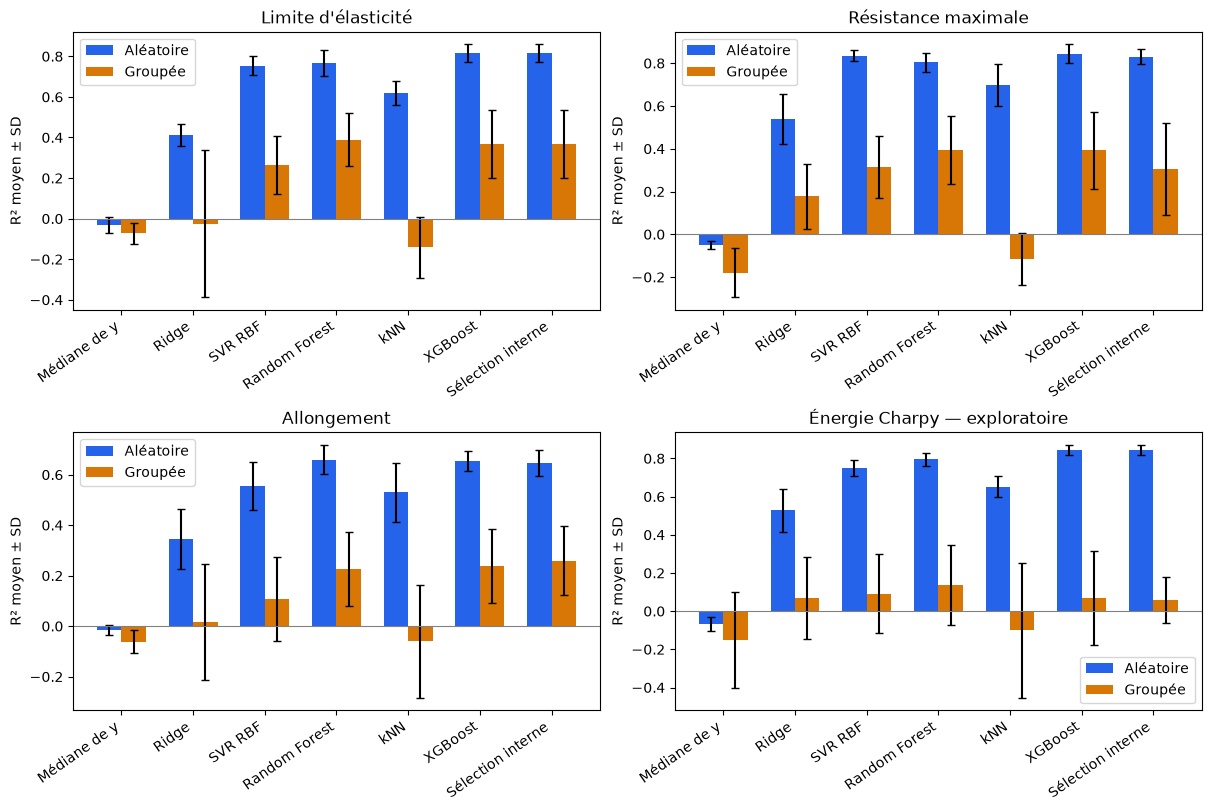

Expérience terminée ; secondes : 84.1


In [8]:
verifier="""import json,cloudpickle,pandas as pd,numpy as np,hashlib,sys
from pathlib import Path
root=Path(sys.argv[1]);out=root/'data/processed/experiments/salh_xgboost_v1'
records=json.loads((out/'reload_records.json').read_text())
master=pd.read_csv(root/'data/processed/modeling/master.csv').set_index('raw_row_id')
preds=pd.read_csv(out/'benchmark_outer_predictions.csv');checks=[]
for a in records:
    path=root/a['path'];meta=json.loads(path.with_suffix('.json').read_text())
    assert hashlib.sha256(path.read_bytes()).hexdigest()==a['sha256']==meta['artifact_sha256']
    with path.open('rb') as stream:model=cloudpickle.load(stream)
    assert model.memory is None
    if a['role']!='full_xgboost':
        assert set(meta['train_raw_row_ids']).isdisjoint(meta['valid_raw_row_ids'])
        if a['protocol']=='grouped':assert set(meta['train_groups']).isdisjoint(meta['valid_groups'])
        name='xgboost' if a['role']=='outer_xgboost' else 'inner_selected'
        p=preds.loc[(preds.protocol==a['protocol'])&(preds.target==a['target'])&(preds.outer_fold==a['outer_fold'])&(preds.model==name)]
        ids=p.raw_row_id.tolist();expected=p.y_pred.to_numpy()
        assert set(ids)==set(meta['valid_raw_row_ids'])
    else:
        ids=meta['probe_raw_row_ids'];expected=np.asarray(meta['probe_predictions'])
    actual=model.predict(master.loc[ids,meta['features']])
    np.testing.assert_allclose(actual,expected,rtol=1e-10,atol=1e-8)
    checks.append({'path':a['path'],'rows_checked':len(ids),'max_abs_difference':float(np.max(np.abs(actual-expected)))})
pd.DataFrame(checks).to_csv(out/'fresh_reload_checks.csv',index=False)
print(json.dumps({'exports':len(checks),'rows_checked':sum(c['rows_checked'] for c in checks)}))
"""
for entry in artifacts:
    if entry['role']=='full_xgboost':
        path=PROJECT_ROOT/entry['path'];meta=json.loads(path.with_suffix('.json').read_text())
        ids=entry['train_raw_row_ids'][:10]
        with path.open('rb') as stream: model=cloudpickle.load(stream)
        meta.update(probe_raw_row_ids=ids,probe_predictions=model.predict(master.set_index('raw_row_id').loc[ids,meta['features']]).tolist())
        path.with_suffix('.json').write_text(json.dumps(meta,indent=2,ensure_ascii=False)+'\n')
(OUT/'reload_records.json').write_text(json.dumps(artifacts,indent=2,ensure_ascii=False)+'\n')
result=subprocess.run([sys.executable,'-c',verifier,str(PROJECT_ROOT)],text=True,capture_output=True,
    env=dict(os.environ,OPENBLAS_NUM_THREADS='1',OMP_NUM_THREADS='1'),check=True)
print(result.stdout)
FIGURES=PROJECT_ROOT/'reports/figures'; FIGURES.mkdir(exist_ok=True)
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for ax,target in zip(axes.ravel(),TARGETS):
    families=FAMILY_ORDER+['inner_selected']; positions=np.arange(len(families))
    for protocol,shift,color in [('random',-.17,'#2563eb'),('grouped',.17,'#d97706')]:
        g=summary.loc[(summary.target==target)&(summary.protocol==protocol)].set_index('model').loc[families]
        ax.bar(positions+shift,g.R2_mean,width=.34,yerr=g.R2_sd,color=color,
            label='Aléatoire' if protocol=='random' else 'Groupée',capsize=3)
    ax.axhline(0,color='gray',linewidth=.8);ax.set_xticks(positions,[MODEL_NAMES.get(f,'Sélection interne') for f in families],rotation=35,ha='right')
    ax.set_ylabel('R² moyen ± SD'); ax.set_title(TARGET_NAMES[target]);ax.legend()
fig.savefig(FIGURES/'17_xgboost_benchmarks_fr.png',dpi=160);plt.show()
source_nb=json.loads((PROJECT_ROOT/'notebooks/08_xgboost.ipynb').read_text())
source_text='\n\n'.join(''.join(c['source']) for c in source_nb['cells'])
manifest={'protocol_version':PROTOCOL_VERSION,'seed':SEED,'feature_set':PRIMARY_SET,
    'imputer':PRIMARY_IMPUTER,'protocols':PROTOCOLS,'grids':PARAM_GRIDS,
    'xgboost_fixed_params':make_pipeline('xgboost','uts').named_steps['model'].get_params(),
    'selection':'MAE interne, égalités selon FAMILY_ORDER ; refits CV5 seed1042 ou GroupKFold5',
    'outer_xgboost_evaluations':len(xgb_scores),'inner_candidates':len(inner_rows),
    'full_candidates':len(full_rows),'xgboost_search_fits':40*(12*3+1)+8*(12*5+1),
    'outer_selections':len(selected_rows),'exports':len(artifacts),'versions':VERSIONS,
    'source_manifests':source_hashes,'raw_sha256':preparation_manifest['raw_sha256'],
    'notebook_source_sha256':hashlib.sha256(source_text.encode()).hexdigest(),
    'elapsed_seconds':time.perf_counter()-STARTED,
    'files':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='manifest.json'},
    'models':{str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(MODELS.rglob('*')) if p.is_file()}}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False)+'\n')
print('Expérience terminée ; secondes :',round(manifest['elapsed_seconds'],1))


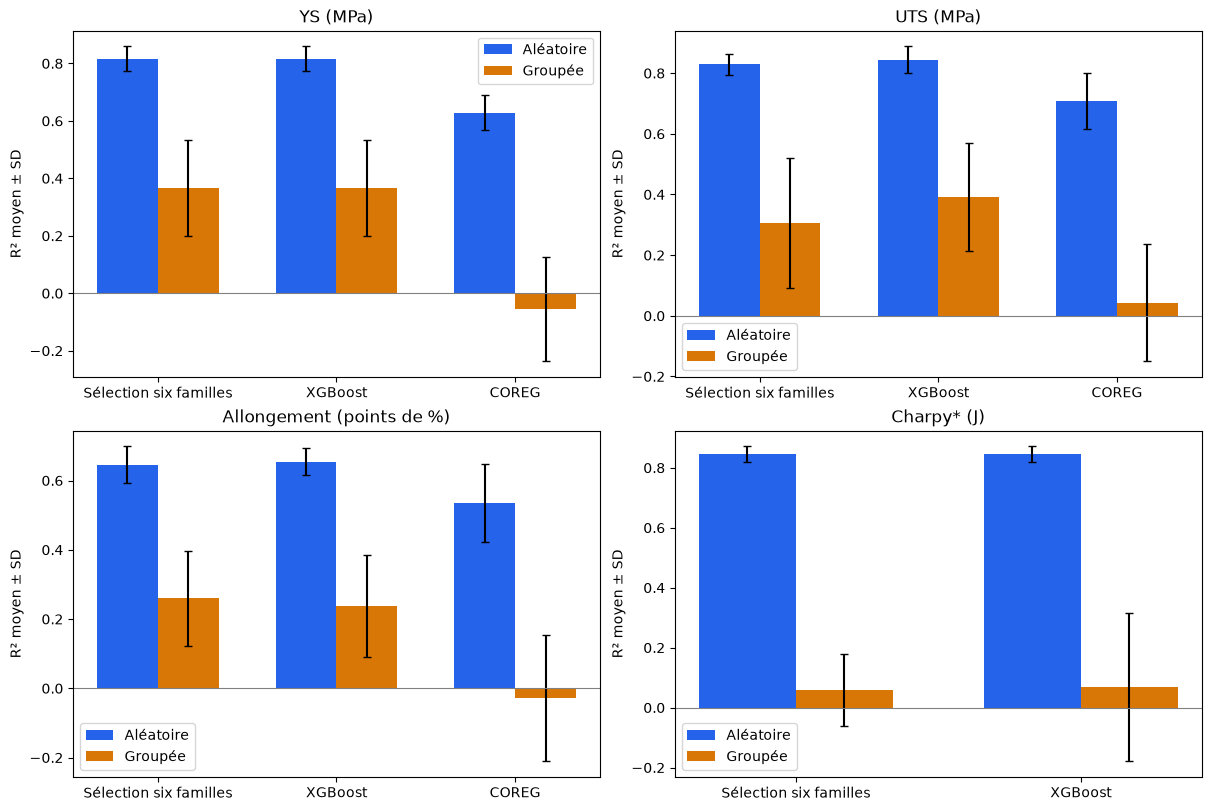

In [9]:
# Figure de synthèse utilisée par les rapports 15 et 16.
# Relire le tableau vérifié permet aussi de régénérer cette figure seule.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'sujet.md').is_file())
combined_plot=pd.read_csv(root/'data/processed/experiments/salh_xgboost_v1/supervised_coreg_summary.csv')
plot_targets=['yield_strength','uts','elongation','charpy_J']
plot_labels=['YS (MPa)','UTS (MPa)','Allongement (points de %)','Charpy* (J)']
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for ax,target,label in zip(axes.ravel(),plot_targets,plot_labels):
    methods=['inner_selected','xgboost']+(['coreg'] if target!='charpy_J' else [])
    positions=np.arange(len(methods))
    for protocol,shift,color in [('random',-.17,'#2563eb'),('grouped',.17,'#d97706')]:
        g=combined_plot.loc[(combined_plot.protocol==protocol)&(combined_plot.target==target)].set_index('model').loc[methods]
        ax.bar(positions+shift,g.R2_mean,width=.34,yerr=g.R2_sd,capsize=3,color=color,
            label='Aléatoire' if protocol=='random' else 'Groupée')
    ax.set_xticks(positions,[{'inner_selected':'Sélection six familles','xgboost':'XGBoost','coreg':'COREG'}[m] for m in methods])
    ax.set_title(label);ax.set_ylabel('R² moyen ± SD');ax.axhline(0,color='gray',lw=.8);ax.legend()
fig.savefig(root/'reports/figures/15_comparaison_globale_fr.png',dpi=160)
plt.show()


## Interprétation

Les résultats chiffrés et limites sont consignés dans
[reports/17_xgboost_training.md](../reports/17_xgboost_training.md),
la synthèse globale et `specs/spec.md`. La demande XGBoost est une extension
postérieure aux investigations sur les mêmes données : aucune validation
indépendante de l'ensemble de la démarche n'est revendiquée. Les limites de
transfert entre séries et d'hétérogénéité Charpy restent à examiner.
